# Chapter 1: The Geometry of Spacetime – Topological Spaces to Manifolds

In [1]:
version()

'SageMath version 10.9, Release Date: 2026-05-04'

Kazi Abu Rousan
Phd, NISER, India

In [2]:
%display latex

## 1. Gravity as Geometry: The Falling Apple
The fundamental insight of General Relativity, stemming from Einstein's **Equivalence Principle**, is that a gravitational field is indistinguishable from acceleration in a locally flat frame. 

**The Apple Thought Experiment:**
Imagine you are in a closed elevator. You hold an apple and let it go, and it accelerates toward the floor at $9.8 \text{ m/s}^2$. Are you resting on the surface of the Earth experiencing a gravitational field, or are you in deep space in a rocket accelerating upwards at $9.8 \text{ m/s}^2$? Einstein argued that there is no local physical experiment you can perform to tell the difference. Gravitational mass (how the apple responds to gravity) and inertial mass (how the apple responds to acceleration) are exactly the same.

Because bodies in free-fall follow paths that are independent of their mass, we interpret these paths not as the result of a "force" acting in a flat background space, but as geodesics through a curved geometry. 

To formalize the concept of a "curved geometry", we must construct the mathematical object known as a **smooth manifold**.

## 2. Topological Spaces
Before defining curvature or distance on abstract curved spaces, we must rigorously define "nearness." We do this by specifying a **topology**. To understand abstract topologies, we first look at the standard topology on flat Euclidean space $\mathbb{R}^n$.

### 2.1 The Open Ball
The fundamental building block of nearness in $\mathbb{R}^n$ is the **Open Ball**. 

**Mathematical Definition (Open Ball):** An open ball of radius $r > 0$ centered at a point $x \in \mathbb{R}^n$, denoted $B_r(x)$, is the set of all points $y$ whose Euclidean distance from $x$ is strictly less than $r$:
$$ B_r(x) = \{ y \in \mathbb{R}^n : |x - y| < r \} $$

Using the open ball, we can strictly define what an **Open Set** is in $\mathbb{R}^n$:
**Mathematical Definition (Open Set in $\mathbb{R}^n$):** A subset $U \subset \mathbb{R}^n$ is an *open set* if, for every point $p \in U$, there exists some open ball $B_r(p)$ that is completely contained entirely within $U$. 
*(In simple terms: you can "wiggle" around any point inside the set in any direction without accidentally stepping outside the set. The boundary is completely excluded!)*

Visualizing an Open Set defined via Open Balls in R^2


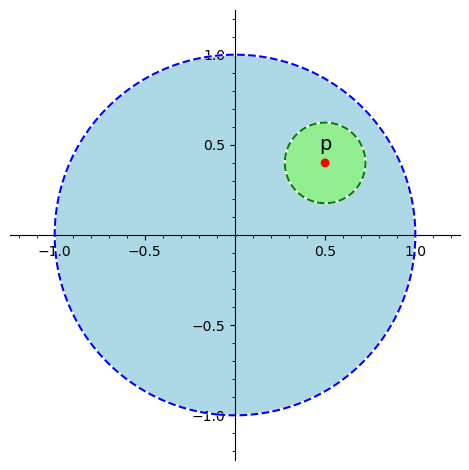

In [3]:
var('x, y')
ball_region = region_plot(x^2 + y^2 < 1, (x, -1.2, 1.2), (y, -1.2, 1.2), incol='lightblue', bordercol='blue', borderstyle='--', plot_points=200)
point_p = point((0.5, 0.4), color='red', size=40, zorder=10)
text_p = text("p", (0.5, 0.5), color='black', fontsize=14)
small_ball = region_plot((x-0.5)^2 + (y-0.4)^2 < 0.05, (x, -1.2, 1.2), (y, -1.2, 1.2), incol='lightgreen', bordercol='green', borderstyle='--', plot_points=200)
print("Visualizing an Open Set defined via Open Balls in R^2")
ball_region + small_ball + point_p + text_p

### 2.2 Abstract Topologies
In an abstract space $M$ where we don't have a concept of "distance" (meaning we have no metric to compute $|x - y|$), we cannot build open sets using balls. Instead, we **axiomatize** the properties of open sets to define an abstract topology!

**Mathematical Definition (Topology):** A *topology* on a set $M$ is a collection $\mathcal{O}$ of subsets of $M$ (called *open sets*) satisfying three axioms:
1. Both the empty set $\emptyset$ and the entire space $M$ are in $\mathcal{O}$ (i.e., $\emptyset \in \mathcal{O}$ and $M \in \mathcal{O}$).
2. The union of an arbitrary collection of sets in $\mathcal{O}$ is also in $\mathcal{O}$: $\bigcup_{i} U_i \in \mathcal{O}$.
3. The intersection of any finite collection of sets in $\mathcal{O}$ is also in $\mathcal{O}$: $U_1 \cap U_2 \cap \dots \cap U_k \in \mathcal{O}$.

### 2.3 The Hausdorff Property, Compactness, and Paracompactness
For physically reasonable spacetimes, we require our topological space to satisfy additional strict properties: it must be **Hausdorff** and **Paracompact**.

**Mathematical Definition (Hausdorff):** A topological space $(M, \mathcal{O})$ is *Hausdorff* if, for any two distinct points $p, q \in M$ ($p \neq q$), there exist open sets $U, V \in \mathcal{O}$ such that $p \in U$, $q \in V$, and $U \cap V = \emptyset$. 
- **Physical Meaning:** If two events in spacetime are distinct, you must be able to put them in separate, non-overlapping "bubbles" (open neighborhoods). Without this, the limit of a sequence of points wouldn't be unique!

Hausdorff Space

**Mathematical Definition (Compactness):** An *open cover* of $M$ is a collection of open sets whose union contains all of $M$. A space is *compact* if every open cover has a finite subcover. 
- **Physical Meaning:** A compact space doesn't stretch out to infinity and doesn't have "missing" boundaries. The 1D circle $S^1$ and the 2D sphere $S^2$ are compact. The real line $\mathbb{R}$ is non-compact.

**Mathematical Definition (Paracompactness):** A space is *paracompact* if every open cover has an open refinement that is "locally finite" (meaning every point has a neighborhood that intersects only finitely many sets in the cover).
- **Physical Meaning:** Spacetimes in General Relativity must be paracompact so we can stitch together local coordinate patches using "partitions of unity" without breaking the math as we approach infinity.

In [4]:
# SageMath Example: Testing the Hausdorff Property
# valid topology O_1 on M = {1, 2, 3}
M_set = Set([1, 2, 3])
empty_set = Set([])
O_1 = [empty_set, Set([1]), Set([1, 2]), M_set]

# Let's test if O_1 is Hausdorff.
# We need to pick two distinct points, say p=1 and q=2.
# Can we find open sets U and V in O_1 such that 1 in U, 2 in V, and U ∩ V = empty?
# Open sets containing 1: {1}, {1, 2}, {1, 2, 3}
# Open sets containing 2: {1, 2}, {1, 2, 3}

# The only open set strictly separating 2 is {1, 2}, but it also contains 1!
# Therefore, U ∩ V will never be empty.
print(f"Topology O_1 = {O_1}")
print("Is O_1 Hausdorff? NO! We cannot separate points 1 and 2 into disjoint open sets.")

# Let's construct a Discrete Topology on {1, 2} which IS Hausdorff
O_discrete = [empty_set, Set([1]), Set([2]), Set([1, 2])]
print(f"\nTopology O_discrete = {O_discrete}")
U = Set([1])
V = Set([2])
print(f"To separate 1 and 2, we choose U={U} and V={V}.")
print(f"Intersection U ∩ V = {U.intersection(V)}. Since it is empty, O_discrete IS Hausdorff!")

Topology O_1 = [{}, {1}, {1, 2}, {1, 2, 3}]
Is O_1 Hausdorff? NO! We cannot separate points 1 and 2 into disjoint open sets.

Topology O_discrete = [{}, {1}, {2}, {1, 2}]
To separate 1 and 2, we choose U={1} and V={2}.
Intersection U ∩ V = {}. Since it is empty, O_discrete IS Hausdorff!


In [5]:
# Let M be a finite set representing our space
M_set = Set([1, 2, 3])
empty_set = Set([])

print(f"Space M = {M_set}")

# Example 1: A VALID Topology
# We define a collection of open sets O_1.
# It contains the empty set, the whole space, and is closed under unions/intersections.
O_1 = [empty_set, Set([1]), Set([1, 2]), M_set]
print(f"\nIs O_1 = {O_1} a valid topology?")
# Let's test union of {1} and {1, 2}
union_test = Set([1]).union(Set([1, 2]))
print(f"Test Union: {{1}} U {{1, 2}} = {union_test}. Is it in O_1? {union_test in O_1} -> YES. O_1 is a valid topology.")

# Example 2: An INVALID Topology
# This collection is missing the union of {1} and {2}
O_2 = [empty_set, Set([1]), Set([2]), M_set]
print(f"\nIs O_2 = {O_2} a valid topology?")
# Let's test union of {1} and {2}
union_test_2 = Set([1]).union(Set([2]))
print(f"Test Union: {{1}} U {{2}} = {union_test_2}. Is it in O_2? {union_test_2 in O_2} -> NO. O_2 is NOT a topology!")

Space M = {1, 2, 3}

Is O_1 = [{}, {1}, {1, 2}, {1, 2, 3}] a valid topology?
Test Union: {1} U {1, 2} = {1, 2}. Is it in O_1? True -> YES. O_1 is a valid topology.

Is O_2 = [{}, {1}, {2}, {1, 2, 3}] a valid topology?
Test Union: {1} U {2} = {1, 2}. Is it in O_2? False -> NO. O_2 is NOT a topology!


## 3. Manifolds and Charts
A **manifold** is a topological space that locally resembles flat Euclidean space $\mathbb{R}^n$.

**Definition:** An *$n$-dimensional manifold* is a topological space $M$ such that every point $p \in M$ has an open neighborhood $U$ that is homeomorphic to an open subset of $\mathbb{R}^n$.

### What is a Chart?
Before we define anything complex, we must understand what a **chart** (or coordinate patch) is. A chart is simply a function $\phi$ that takes an abstract physical point $p$ on the manifold and assigns it an $n$-tuple of real numbers $(x^1, x^2, \dots, x^n)$.

**Example:** Think of the Earth (a curved 2D manifold). A physical city like "Paris" is an abstract point $p$. A chart $\phi$ is the GPS system that takes the point "Paris" and maps it to a flat 2D coordinate grid: $\phi(\text{Paris}) = (48.8, 2.3)$. The collection of all these maps forms an **Atlas**.

A **homeomorphism** is a bijective function $\phi : U \to \phi(U) \subset \mathbb{R}^n$ that is continuous, and whose inverse $\phi^{-1}$ is also continuous.

## 4. Atlases and Transition Functions
When multiple charts overlap, we need a rule to translate coordinates between them.

**Definition:** An *atlas* is a collection of charts $\{(U_\alpha, \phi_\alpha)\}$ such that the open sets $U_\alpha$ completely cover the manifold: $M = \bigcup_\alpha U_\alpha$.

If two charts $(U_\alpha, \phi_\alpha)$ and $(U_\beta, \phi_\beta)$ overlap (i.e., $U_\alpha \cap U_\beta \neq \emptyset$), we can translate coordinates between them using a **transition map**:
$$ \phi_\beta \circ \phi_\alpha^{-1} : \phi_\alpha(U_\alpha \cap U_\beta) \to \phi_\beta(U_\alpha \cap U_\beta) $$
This transition map takes coordinates in $\mathbb{R}^n$ from chart $\alpha$, maps them back to the abstract point $p$ on the manifold via $\phi_\alpha^{-1}$, and then maps $p$ into the coordinates of chart $\beta$ via $\phi_\beta$. For a *smooth manifold*, we require all such transition maps to be infinitely differentiable ($C^\infty$).

Manifold Atlas

### 4.1 Example: The 1D Circle ($S^1$)
A common misconception is that a manifold can always be covered by a single coordinate grid. The unit circle $S^1$ is a 1-dimensional manifold, but we **cannot** map the entire circle with just one chart without creating a singularity or a jump discontinuity. If we define an angle $\theta \in (0, 2\pi)$, the point at $\theta = 0$ is exactly the same physical point as $\theta = 2\pi$, creating a severe coordinate singularity. 

To rigorously cover $S^1$, we need an atlas with at least **two** overlapping charts:
1. $U_1$: Covers the circle except the North pole. Map $\phi_1 : \theta_1 \in (0, 2\pi)$.
2. $U_2$: Covers the circle except the South pole. Map $\phi_2 : \theta_2 \in (-\pi, \pi)$.

**Deriving the Transition Map for $S^1$:**
The overlap $W = U_1 \cap U_2$ consists of two disconnected regions: the right half of the circle and the left half.
- On the right half, $\theta_1 \in (0, \pi)$. Since this matches standard angles, $\theta_2 = \theta_1$.
- On the left half, $\theta_1 \in (\pi, 2\pi)$. To map this into $(-\pi, \pi)$, we must shift it: $\theta_2 = \theta_1 - 2\pi$.

Let's program this explicit transition and plot the overlapping charts in SageMath!

In [6]:
# Constructing a 1-dimensional manifold S^1
S1 = Manifold(1, 'S^1', r'\mathbb{S}^1')

# Define two open subsets to avoid coordinate singularities
U1 = S1.open_subset('U_1') # Missing North Pole
U2 = S1.open_subset('U_2') # Missing South Pole
S1.declare_union(U1, U2)

# Define charts for both open sets
phi_1.<th_1> = U1.chart(r'th_1:(0,2*pi):\theta_1')
phi_2.<th_2> = U2.chart(r'th_2:(-pi,pi):\theta_2')

# Define the rigorous transition map between the charts
# Because the overlap is disconnected, we define it piecewise
trans = phi_1.transition_map(phi_2, [th_1], intersection_name='W', restrictions1=th_1!=pi, restrictions2=th_2!=0)

print("Transition Map defined on the overlap W:")
trans.display()

# # To plot the circle, we embed S^1 into flat R^2
# R2 = Manifold(2, 'R^2', r'\mathbb{R}^2')
# X2.<X,Y> = R2.chart()

# # The mapping from each chart to R^2
# F1 = U1.diff_map(R2, [cos(th_1), sin(th_1)])
# F2 = U2.diff_map(R2, [cos(th_2), sin(th_2)])

# # Plot U1 in red, and U2 in blue dashed to show how they overlap to cover the whole circle!
# plot1 = phi_1.plot(chart=X2, mapping=F1, color='red', thickness=4)
# # plot2 = phi_2.plot(chart=X2, mapping=F2, color='blue', thickness=2, style='--')

# plot1# + plot2

Transition Map defined on the overlap W:


th_2 = th_1

### 4.2 Example: The 2D Sphere ($S^2$) and Stereographic Projection
Just like the circle, the 2-dimensional sphere $S^2$ cannot be covered by a single chart. Standard spherical coordinates $(\theta, \varphi)$ fail completely at the poles (all values of $\varphi$ map to the exact same physical point at the North pole!).

Instead, we construct an atlas for $S^2$ using two stereographic charts. We place the sphere on the plane $z=0$. 
1. $U_N = S^2 \setminus \{ \text{North Pole} \}$: We draw a line from the North pole $(0,0,1)$ through the point $p$ on the sphere to the plane. The intersection gives flat coordinates $(X_N, Y_N)$.
2. $U_S = S^2 \setminus \{ \text{South Pole} \}$: We draw a line from the South pole $(0,0,-1)$ to the plane. The intersection gives flat coordinates $(X_S, Y_S)$.

**Deriving the Transition Map for $S^2$:**
For a point $p$ in the overlap $W = U_N \cap U_S$, we can translate the coordinates from the North chart to the South chart using basic geometry (similar triangles). The transition function is:
$$ X_S = \frac{X_N}{X_N^2 + Y_N^2}, \quad Y_S = \frac{Y_N}{X_N^2 + Y_N^2} $$
Notice that this map is perfectly smooth ($C^\infty$) everywhere except at $(0,0)$, which corresponds to the poles we explicitly excluded!

In [7]:
# Construct the 2-dimensional sphere S^2
M = Manifold(2, 'S^2', r'\mathbb{S}^2')

# Define North Chart U_N (x, y)
U_N = M.open_subset('U_N')
phi_N.<x, y> = U_N.chart()

# Define South Chart U_S (u, v)
U_S = M.open_subset('U_S')
phi_S.<u, v> = U_S.chart()
M.declare_union(U_N, U_S)

# Compute the rigorous transition map from phi_N to phi_S
trans_S2 = phi_N.transition_map(
    phi_S, 
    [x/(x^2+y^2), y/(x^2+y^2)], 
    intersection_name='W', 
    restrictions1 = x^2+y^2 != 0, 
    restrictions2 = u^2+v^2 != 0
)

print("Transition map for Stereographic Projection (phi_S ∘ phi_N^{-1}):")
trans_S2.display()

Transition map for Stereographic Projection (phi_S ∘ phi_N^{-1}):


u = x/(x^2 + y^2)
v = y/(x^2 + y^2)

### 4.3 SageMath Plot: Visualizing the North Chart
To rigorously visualize the stereographic projection, we must tell SageMath how to draw our abstract 2D manifold inside a 3D viewing space.

We do this using a **Differentiable Map** (`diff_map`). A differentiable map is simply a smooth function that takes points from one manifold and maps them into another. 

Here, we define a map $F_N : U_N \to \mathbb{R}^3$. It takes the flat 2D coordinates $(x, y)$ from our North chart and maps them to the 3D Cartesian coordinates $(X, Y, Z)$ using the exact mathematical **inverse of the stereographic projection**:
$$ X = \frac{2x}{1+x^2+y^2}, \quad Y = \frac{2y}{1+x^2+y^2}, \quad Z = \frac{x^2+y^2-1}{1+x^2+y^2} $$

By providing this `diff_map` to the plotting engine, SageMath knows exactly how to wrap the flat 2D grid onto the 3D spherical surface!

*(Note: We explicitly command SageMath to plot the coordinate grid using red lines for constant $x$ and blue lines for constant $y$.)*

In [8]:
# Define the embedding space R^3
R3 = Manifold(3, 'R^3', r'\mathbb{R}^3')
X3.<X,Y,Z> = R3.chart()

# Embedding function for the North Chart
F_N = U_N.diff_map(R3, [2*x/(1+x^2+y^2), 2*y/(1+x^2+y^2), (x^2+y^2-1)/(1+x^2+y^2)], name='F_N')

# Plot the coordinate grid curves on the sphere
# We explicitly set x lines to red and y lines to blue!
plot_N = phi_N.plot(chart=X3, mapping=F_N, number_values=20, thickness=1.5, max_range=2.5, color={x: 'red', y: 'blue'})
plot_N

Graphics3d Object

## 5. Product Manifolds
A powerful way to construct new mathematical structures is by taking the Cartesian product of two known manifolds.

**Definition:** If $M$ is an $m$-dimensional manifold and $N$ is an $n$-dimensional manifold, the product space $M \times N$ is an $(m+n)$-dimensional manifold.

### 5.1 Example: The Cylinder ($S^1 \times \mathbb{R}$)
If we take the 1-dimensional circle $S^1$ and cross it with the 1-dimensional real line $\mathbb{R}$, we generate a 2-dimensional cylinder. Let's explicitly define this in SageMath and plot it.

In [9]:
# Define the cylinder as a 2D manifold
Cyl = Manifold(2, 'Cyl', r'S^1 \times \mathbb{R}')

# The chart uses an angular coordinate (theta) and a height coordinate (z)
C_chart.<th_c, z> = Cyl.chart(r'th_c:(0,2*pi):\theta z')

# Embedding the cylinder into R^3 for plotting
F_cyl = Cyl.diff_map(R3, [cos(th_c), sin(th_c), z], name='F_cyl')

# Plotting the product manifold coordinate grid
plot_cyl = C_chart.plot(chart=X3, mapping=F_cyl, number_values=15, max_range=2, thickness=1.5, color={th_c: 'red', z: 'blue'})
plot_cyl

Graphics3d Object

## Appendix: SageMath Functions Used

For reference, here is a glossary of the primary SageMath (SageManifolds) functions used in this notebook, their inputs, and outputs:

### Set Theory
*   **`Set(list)`**
    *   **Input**: A Python list of elements (e.g., `[1, 2, 3]`).
    *   **Output**: A mathematical Set object capable of rigorous set operations.
*   **`set1.union(set2)`** / **`set1.intersection(set2)`**
    *   **Input**: Another Set object.
    *   **Output**: A new Set representing the strict mathematical union or intersection.

### Manifolds and Subsets
*   **`Manifold(dim, name, latex_name)`**
    *   **Input**: Integer dimension (`dim`), a string `name`, and an optional `latex_name` for rendering.
    *   **Output**: A smooth abstract manifold object.
*   **`M.open_subset(name)`**
    *   **Input**: A string `name`.
    *   **Output**: An open subset object belonging to manifold `M`.
*   **`M.declare_union(U1, U2)`**
    *   **Input**: Two subset objects `U1` and `U2`.
    *   **Output**: None. (Modifies `M` to mathematically declare that the union of `U1` and `U2` covers the entire manifold `M`).

### Charts and Mappings
*   **`U.chart(coordinate_string)`**
    *   **Input**: A formatted string defining the coordinates and their bounds (e.g., `'th:(0,2*pi)'`).
    *   **Output**: A Chart object representing a local coordinate patch on `U`.
*   **`phi_1.transition_map(phi_2, [exprs], intersection_name, restrictions)`**
    *   **Input**: A target chart (`phi_2`), a list of mathematical expressions translating the coordinates, a name for the overlapping region, and optional inequality restrictions.
    *   **Output**: A TransitionMap object that can translate tensor components between the two charts.
*   **`U.diff_map(target_manifold, [exprs], name)`**
    *   **Input**: A target manifold object (like $\mathbb{R}^3$), a list of coordinate mapping expressions, and a string name.
    *   **Output**: A Differentiable Map object representing a smooth function from `U` into `target_manifold` (commonly used for embeddings).
*   **`chart.plot(chart=target_chart, mapping=map, color, thickness, ...)`**
    *   **Input**: The viewing chart (e.g., Cartesian $\mathbb{R}^3$), the differentiable map defining the embedding, and styling kwargs.
    *   **Output**: A Sage Graphics object rendering the coordinate grid of `chart` in the target space.